In [2]:

import os
import pandas as pd

files = sorted([
    f for f in os.listdir("/content")
    if f.endswith(".parquet")
])

print("Dataset files:", len(files))
print("\n".join(files))


Dataset files: 8
Benign-Monday-no-metadata.parquet
Botnet-Friday-no-metadata.parquet
Bruteforce-Tuesday-no-metadata.parquet
DDoS-Friday-no-metadata.parquet
DoS-Wednesday-no-metadata.parquet
Infiltration-Thursday-no-metadata.parquet
Portscan-Friday-no-metadata.parquet
WebAttacks-Thursday-no-metadata.parquet


In [3]:

import numpy as np
import pandas as pd
import os

RANDOM_STATE = 42
SAMPLES_PER_CLASS = 10000

benign_parts = []
attack_parts = []

for file in files:
    data = pd.read_parquet(os.path.join("/content", file))

    data["Binary_Label"] = (
        data["Label"].astype(str).str.strip() != "Benign"
    ).astype(int)

    benign = data[data["Binary_Label"] == 0]
    attack = data[data["Binary_Label"] == 1]

    if len(benign) > 0:
        benign_parts.append(
            benign.sample(
                n=min(2000, len(benign)),
                random_state=RANDOM_STATE
            )
        )

    if len(attack) > 0:
        attack_parts.append(
            attack.sample(
                n=min(3000, len(attack)),
                random_state=RANDOM_STATE
            )
        )

benign_data = pd.concat(benign_parts, ignore_index=True)
attack_data = pd.concat(attack_parts, ignore_index=True)

benign_data = benign_data.sample(
    n=min(SAMPLES_PER_CLASS, len(benign_data)),
    random_state=RANDOM_STATE
)

attack_data = attack_data.sample(
    n=min(SAMPLES_PER_CLASS, len(attack_data)),
    random_state=RANDOM_STATE
)

dataset = pd.concat(
    [benign_data, attack_data],
    ignore_index=True
).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print("Final dataset shape:", dataset.shape)
print("\nBinary class distribution:")
print(dataset["Binary_Label"].value_counts())

print("\nOriginal attack types:")
print(dataset["Label"].value_counts())


Final dataset shape: (20000, 79)

Binary class distribution:
Binary_Label
1    10000
0    10000
Name: count, dtype: int64

Original attack types:
Label
Benign                        10000
DDoS                           2044
DoS Hulk                       1870
FTP-Patator                    1344
PortScan                       1296
Bot                            1006
Web Attack � Brute Force       1004
SSH-Patator                     738
Web Attack � XSS                440
DoS GoldenEye                    97
DoS slowloris                    63
DoS Slowhttptest                 56
Infiltration                     26
Web Attack � Sql Injection       16
Name: count, dtype: int64


In [4]:

import numpy as np
from sklearn.model_selection import train_test_split

# 1. Separate features and labels
X = dataset.drop(columns=["Label", "Binary_Label"])
y = dataset["Binary_Label"]

# 2. Clean the data
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

# 3. Remove duplicate feature patterns
unique = ~X.duplicated()
X = X.loc[unique]
y = y.loc[unique]

# 4. Split into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 5. Check results
print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Missing values:", X.isna().sum().sum())
print("Duplicate rows:", X.duplicated().sum())

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

overlap = len(
    set(map(tuple, X_train.to_numpy())) &
    set(map(tuple, X_test.to_numpy()))
)
print("\nDuplicate patterns across train/test:", overlap)


Total records: 19993
Training records: 15994
Testing records: 3999
Missing values: 0
Duplicate rows: 0

Training labels:
Binary_Label
1    7999
0    7995
Name: count, dtype: int64

Testing labels:
Binary_Label
1    2000
0    1999
Name: count, dtype: int64

Duplicate patterns across train/test: 0


In [5]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.impute import SimpleImputer
import time

# 1. Handle any missing values using training data only
imputer = SimpleImputer(strategy="median")
X_train_ready = imputer.fit_transform(X_train)
X_test_ready = imputer.transform(X_test)

# 2. Create the baseline Random Forest model
baseline_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# 3. Train the model
start_time = time.time()

baseline_model.fit(X_train_ready, y_train)

training_time = time.time() - start_time

# 4. Test the model on clean, unseen data
baseline_predictions = baseline_model.predict(X_test_ready)

# 5. Calculate performance
baseline_results = {
    "Model": "Baseline",
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, zero_division=0),
    "F1-score": f1_score(y_test, baseline_predictions, zero_division=0)
}

print("BASELINE MODEL RESULTS")
print("----------------------")

for metric, value in baseline_results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float)
          else f"{metric}: {value}")

print(f"\nTraining time: {training_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=["Benign", "Attack"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))


BASELINE MODEL RESULTS
----------------------
Model: Baseline
Accuracy: 0.9927
Precision: 0.9970
Recall: 0.9885
F1-score: 0.9927

Training time: 10.45 seconds

Classification Report:
              precision    recall  f1-score   support

      Benign       0.99      1.00      0.99      1999
      Attack       1.00      0.99      0.99      2000

    accuracy                           0.99      3999
   macro avg       0.99      0.99      0.99      3999
weighted avg       0.99      0.99      0.99      3999


Confusion Matrix:
[[1993    6]
 [  23 1977]]


In [6]:

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

RANDOM_STATE = 42
poisoning_levels = [0.05, 0.10, 0.20]
poisoning_results = []
poisoned_models = {}

for level in poisoning_levels:

    # Copy the original clean training labels
    y_poisoned = y_train.to_numpy().copy()

    # Randomly select labels to flip
    rng = np.random.default_rng(RANDOM_STATE)
    n_flip = int(round(level * len(y_poisoned)))
    flip_indices = rng.choice(
        len(y_poisoned), size=n_flip, replace=False
    )

    # Binary label flipping: 0 becomes 1, 1 becomes 0
    y_poisoned[flip_indices] = 1 - y_poisoned[flip_indices]

    # Train a new model using poisoned labels
    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(X_train_ready, y_poisoned)
    predictions = model.predict(X_test_ready)

    # Evaluate on the same clean test set
    result = {
        "Model": f"Poisoned {int(level * 100)}%",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    poisoning_results.append(result)
    poisoned_models[level] = model

    print(f"\nPoisoning Level: {int(level * 100)}%")
    print("Labels flipped:", n_flip)
    print("Accuracy:", round(result["Accuracy"], 4))
    print("Precision:", round(result["Precision"], 4))
    print("Recall:", round(result["Recall"], 4))
    print("F1-score:", round(result["F1-score"], 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

# Summary table
poisoning_df = pd.DataFrame(poisoning_results)

print("\nPOISONING EXPERIMENT SUMMARY")
display(poisoning_df)



Poisoning Level: 5%
Labels flipped: 800
Accuracy: 0.9852
Precision: 0.9904
Recall: 0.98
F1-score: 0.9852
Confusion Matrix:
[[1980   19]
 [  40 1960]]

Poisoning Level: 10%
Labels flipped: 1599
Accuracy: 0.9757
Precision: 0.9823
Recall: 0.969
F1-score: 0.9756
Confusion Matrix:
[[1964   35]
 [  62 1938]]

Poisoning Level: 20%
Labels flipped: 3199
Accuracy: 0.9365
Precision: 0.9482
Recall: 0.9235
F1-score: 0.9357
Confusion Matrix:
[[1898  101]
 [ 153 1847]]

POISONING EXPERIMENT SUMMARY


,Model,Accuracy,Precision,Recall,F1-score
0,Poisoned 5%,0.985246,0.990399,0.9800,0.985172
1,Poisoned 10%,0.975744,0.982261,0.9690,0.975585
2,Poisoned 20%,0.936484,0.948152,0.9235,0.935664


In [7]:

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

defence_results = []

# Use the same poisoning levels
for level in [0.05, 0.10, 0.20]:

    # Recreate the poisoned training labels
    y_poisoned = y_train.to_numpy().copy()
    rng = np.random.default_rng(42)
    n_flip = int(round(level * len(y_poisoned)))
    flip_indices = rng.choice(
        len(y_poisoned), size=n_flip, replace=False
    )
    y_poisoned[flip_indices] = 1 - y_poisoned[flip_indices]

    # Generate out-of-fold predictions
    cv = StratifiedKFold(
        n_splits=3, shuffle=True, random_state=42
    )

    oof_predictions = np.zeros(len(y_poisoned), dtype=int)

    for train_idx, val_idx in cv.split(
        X_train_ready, y_poisoned
    ):
        detector = RandomForestClassifier(
            n_estimators=50,
            random_state=42,
            n_jobs=-1
        )

        detector.fit(
            X_train_ready[train_idx],
            y_poisoned[train_idx]
        )

        oof_predictions[val_idx] = detector.predict(
            X_train_ready[val_idx]
        )

    # Keep records with consistent labels
    keep_mask = oof_predictions == y_poisoned

    X_filtered = X_train_ready[keep_mask]
    y_filtered = y_poisoned[keep_mask]

    # Train the defended model
    defended_model = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    defended_model.fit(X_filtered, y_filtered)
    predictions = defended_model.predict(X_test_ready)

    result = {
        "Model": f"Defended {int(level * 100)}%",
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    defence_results.append(result)

    # Diagnostic: how many truly flipped labels were flagged?
    flagged = ~keep_mask
    truly_flipped = np.zeros(len(y_poisoned), dtype=bool)
    truly_flipped[flip_indices] = True

    print(f"\nDEFENCE AT {int(level * 100)}% POISONING")
    print("Training records removed:", flagged.sum())
    print("Flipped labels detected:", (flagged & truly_flipped).sum())
    print("Clean labels incorrectly removed:",
          (flagged & ~truly_flipped).sum())
    print("Accuracy:", round(result["Accuracy"], 4))
    print("F1-score:", round(result["F1-score"], 4))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))

defence_df = pd.DataFrame(defence_results)

print("\nDEFENCE RESULTS SUMMARY")
display(defence_df)



DEFENCE AT 5% POISONING
Training records removed: 1092
Flipped labels detected: 784
Clean labels incorrectly removed: 308
Accuracy: 0.9857
F1-score: 0.9856
Confusion Matrix:
[[1986   13]
 [  44 1956]]

DEFENCE AT 10% POISONING
Training records removed: 1985
Flipped labels detected: 1540
Clean labels incorrectly removed: 445
Accuracy: 0.983
F1-score: 0.9829
Confusion Matrix:
[[1979   20]
 [  48 1952]]

DEFENCE AT 20% POISONING
Training records removed: 3904
Flipped labels detected: 2931
Clean labels incorrectly removed: 973
Accuracy: 0.9737
F1-score: 0.9735
Confusion Matrix:
[[1964   35]
 [  70 1930]]

DEFENCE RESULTS SUMMARY


,Model,Accuracy,Precision,Recall,F1-score
0,Defended 5%,0.985746,0.993398,0.978,0.985639
1,Defended 10%,0.982996,0.989858,0.976,0.982880
2,Defended 20%,0.973743,0.982188,0.965,0.973518


FINAL EXPERIMENT RESULTS


,Model,Accuracy,Precision,Recall,F1-score
0,Baseline,0.9927,0.9970,0.9885,0.9927
1,Poisoned 5%,0.9852,0.9904,0.9800,0.9852
2,Defended 5%,0.9857,0.9934,0.9780,0.9856
3,Poisoned 10%,0.9757,0.9823,0.9690,0.9756
4,Defended 10%,0.9830,0.9899,0.9760,0.9829
5,Poisoned 20%,0.9365,0.9482,0.9235,0.9357
6,Defended 20%,0.9737,0.9822,0.9650,0.9735


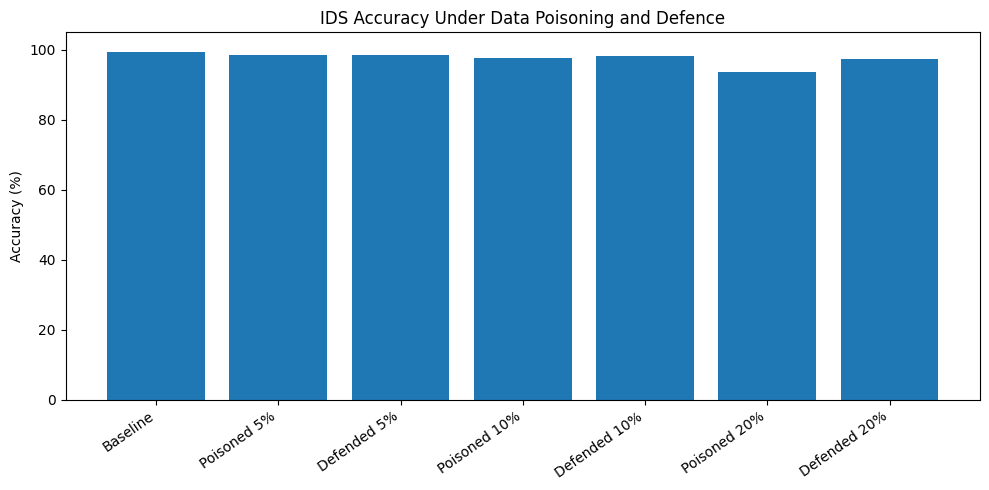

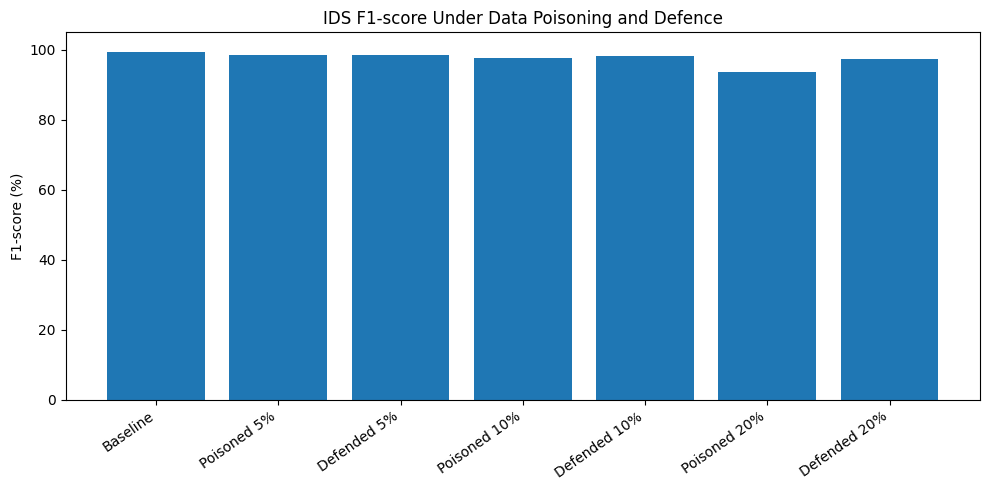

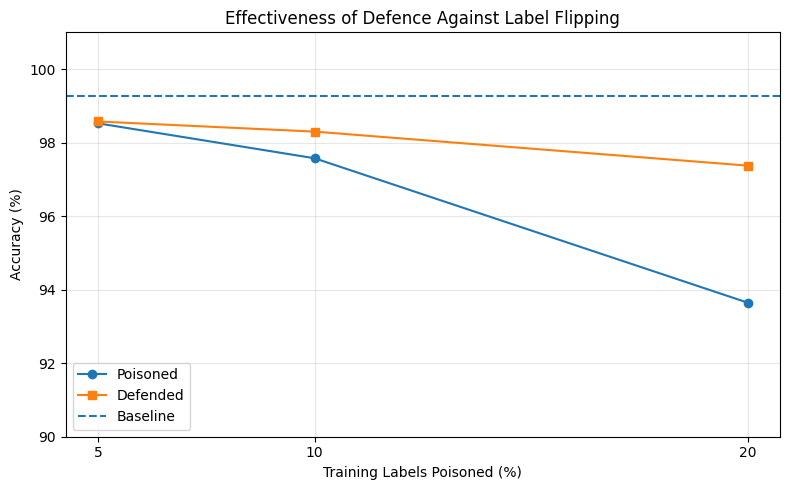


Saved files:
['f1_comparison.png', 'defence_effectiveness.png', 'accuracy_comparison.png', 'model_comparison.csv']


In [8]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Combine all model results
results_df = pd.concat([
    pd.DataFrame([baseline_results]),
    poisoning_df,
    defence_df
], ignore_index=True)

# Arrange models in experimental order
model_order = [
    "Baseline",
    "Poisoned 5%", "Defended 5%",
    "Poisoned 10%", "Defended 10%",
    "Poisoned 20%", "Defended 20%"
]

results_df["Model"] = pd.Categorical(
    results_df["Model"],
    categories=model_order,
    ordered=True
)

results_df = results_df.sort_values("Model").reset_index(drop=True)

# Display summary table
print("FINAL EXPERIMENT RESULTS")
display(results_df.round(4))

# Create results folder
os.makedirs("/content/results", exist_ok=True)

# Save results table
results_df.to_csv(
    "/content/results/model_comparison.csv",
    index=False
)

# Graph 1: Accuracy comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["Accuracy"] * 100)
plt.ylabel("Accuracy (%)")
plt.title("IDS Accuracy Under Data Poisoning and Defence")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("/content/results/accuracy_comparison.png", dpi=300)
plt.show()

# Graph 2: F1-score comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["F1-score"] * 100)
plt.ylabel("F1-score (%)")
plt.title("IDS F1-score Under Data Poisoning and Defence")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig("/content/results/f1_comparison.png", dpi=300)
plt.show()

# Graph 3: Poisoned vs defended accuracy
levels = [5, 10, 20]

poisoned_accuracy = [
    poisoning_df.iloc[i]["Accuracy"] * 100
    for i in range(3)
]

defended_accuracy = [
    defence_df.iloc[i]["Accuracy"] * 100
    for i in range(3)
]

plt.figure(figsize=(8, 5))
plt.plot(levels, poisoned_accuracy, marker="o",
         label="Poisoned")
plt.plot(levels, defended_accuracy, marker="s",
         label="Defended")
plt.axhline(
    baseline_results["Accuracy"] * 100,
    linestyle="--",
    label="Baseline"
)
plt.xlabel("Training Labels Poisoned (%)")
plt.ylabel("Accuracy (%)")
plt.title("Effectiveness of Defence Against Label Flipping")
plt.xticks(levels)
plt.ylim(90, 101)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/results/defence_effectiveness.png", dpi=300)
plt.show()

print("\nSaved files:")
print(os.listdir("/content/results"))


In [9]:

# Automated validation tests

assert X_train.shape[1] == X_test.shape[1], \
    "Training and testing features do not match."

assert X_train.isna().sum().sum() == 0, \
    "Training data contains missing values."

assert X_test.isna().sum().sum() == 0, \
    "Testing data contains missing values."

assert set(y_train.unique()) == {0, 1}, \
    "Training labels must be binary."

assert set(y_test.unique()) == {0, 1}, \
    "Testing labels must be binary."

assert len(results_df) == 7, \
    "Expected 7 model results."

assert results_df["Accuracy"].between(0, 1).all(), \
    "Accuracy values must be between 0 and 1."

assert results_df["F1-score"].between(0, 1).all(), \
    "F1-score values must be between 0 and 1."

print("All 8 automated validation tests passed!")


All 8 automated validation tests passed!
